# Phase 1: Enhancement (sama, LIVER, patient 0)

| Step | sama's algorithms |
|---|---|
| Windowing | abdomen window, level 40 / width 400 |
| Spatial filter | **bilateral** (edge-preserving) vs **median** |
| Contrast | **CLAHE** vs **histogram equalisation** |
| Frequency | 2D DFT spectrum + **Butterworth lowpass** (D0 = 60, order 2) |
| Validation | PSNR + CNR (liver vs surroundings, tumour vs liver) |

In [1]:
import os, glob
import numpy as np
import cv2
import matplotlib.pyplot as plt
import pandas as pd

NAME = "sama"                              # your slices folder
SLICES = f"../data/slices/{NAME}"
OUT = "outputs_sama"                            # creates phase1/outputs_sama
FIGS = "../report/figures/sama"
os.makedirs(f"{OUT}/enhanced", exist_ok=True)
os.makedirs(FIGS, exist_ok=True)

files = sorted(glob.glob(f"{SLICES}/*_ct.npy"))
print(len(files), "slices found")

def load(ct_path):
    """Load one slice: raw CT (HU) + liver mask + tumour mask (True/False)."""
    base = ct_path.replace("_ct.npy", "")
    ct = np.load(ct_path)
    liver = cv2.imread(base + "_liver.png", 0) > 0
    tumour = cv2.imread(base + "_tumour.png", 0) > 0
    return ct, liver, tumour

# pick the slice with the biggest tumour to show in the figures
example = max(files, key=lambda f: load(f)[2].sum())
ct, liver, tumour = load(example)
print("example slice:", os.path.basename(example), "| tumour pixels:", tumour.sum())

16 slices found


example slice: p0_s58_ct.npy | tumour pixels: 538


**Windowing:** keep only -160 to 240 HU (soft tissue) and stretch it to 0-255.

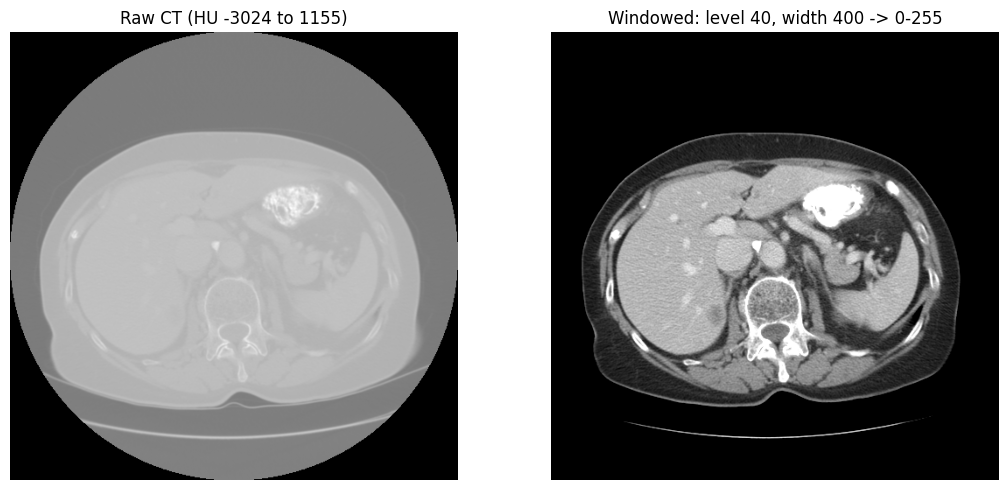

In [2]:
def window(ct, level=40, width=400):
    """Keep only the soft-tissue HU range (abdomen window) and scale it to 0-255."""
    lo, hi = level - width / 2, level + width / 2      # 40, 400 -> -160 to 240 HU
    img = np.clip(ct, lo, hi)                          # everything outside -> lo or hi
    img = (img - lo) / (hi - lo) * 255                 # stretch to 0-255
    return img.astype(np.uint8)

win = window(ct)

def crop(img):
    """Zoom on the abdomen centre so the liver is easier to see in figures."""
    return img[100:420, 40:400]

fig, ax = plt.subplots(1, 2, figsize=(11, 5))
ax[0].imshow(ct, cmap="gray"); ax[0].set_title(f"Raw CT (HU {ct.min():.0f} to {ct.max():.0f})")
ax[1].imshow(win, cmap="gray"); ax[1].set_title("Windowed: level 40, width 400 -> 0-255")
for a in ax: a.axis("off")
plt.tight_layout(); plt.savefig(f"{FIGS}/{NAME}_p1_windowing.png", dpi=120); plt.show()

**Spatial filtering:** bilateral averages only pixels that are close *and* similar in brightness (keeps edges); median takes the middle value of each 5x5 neighbourhood.

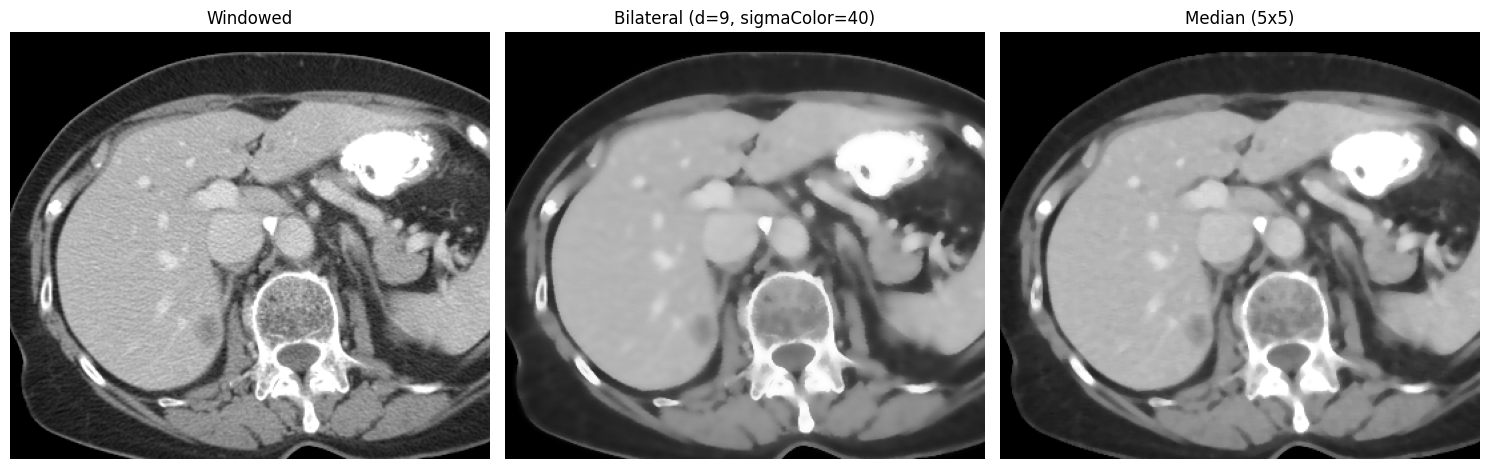

In [3]:
bilateral = cv2.bilateralFilter(win, d=9, sigmaColor=40, sigmaSpace=9)
median = cv2.medianBlur(win, 5)

fig, ax = plt.subplots(1, 3, figsize=(15, 5))
for a, im, t in zip(ax, [win, bilateral, median],
                     ["Windowed", "Bilateral (d=9, sigmaColor=40)", "Median (5x5)"]):
    a.imshow(crop(im), cmap="gray"); a.set_title(t); a.axis("off")
plt.tight_layout(); plt.savefig(f"{FIGS}/{NAME}_p1_spatial_filters.png", dpi=120); plt.show()

**Contrast:** HE spreads brightness over 0-255 for the whole image; CLAHE does it in 8x8 tiles with a clip limit so noise is not over-boosted.

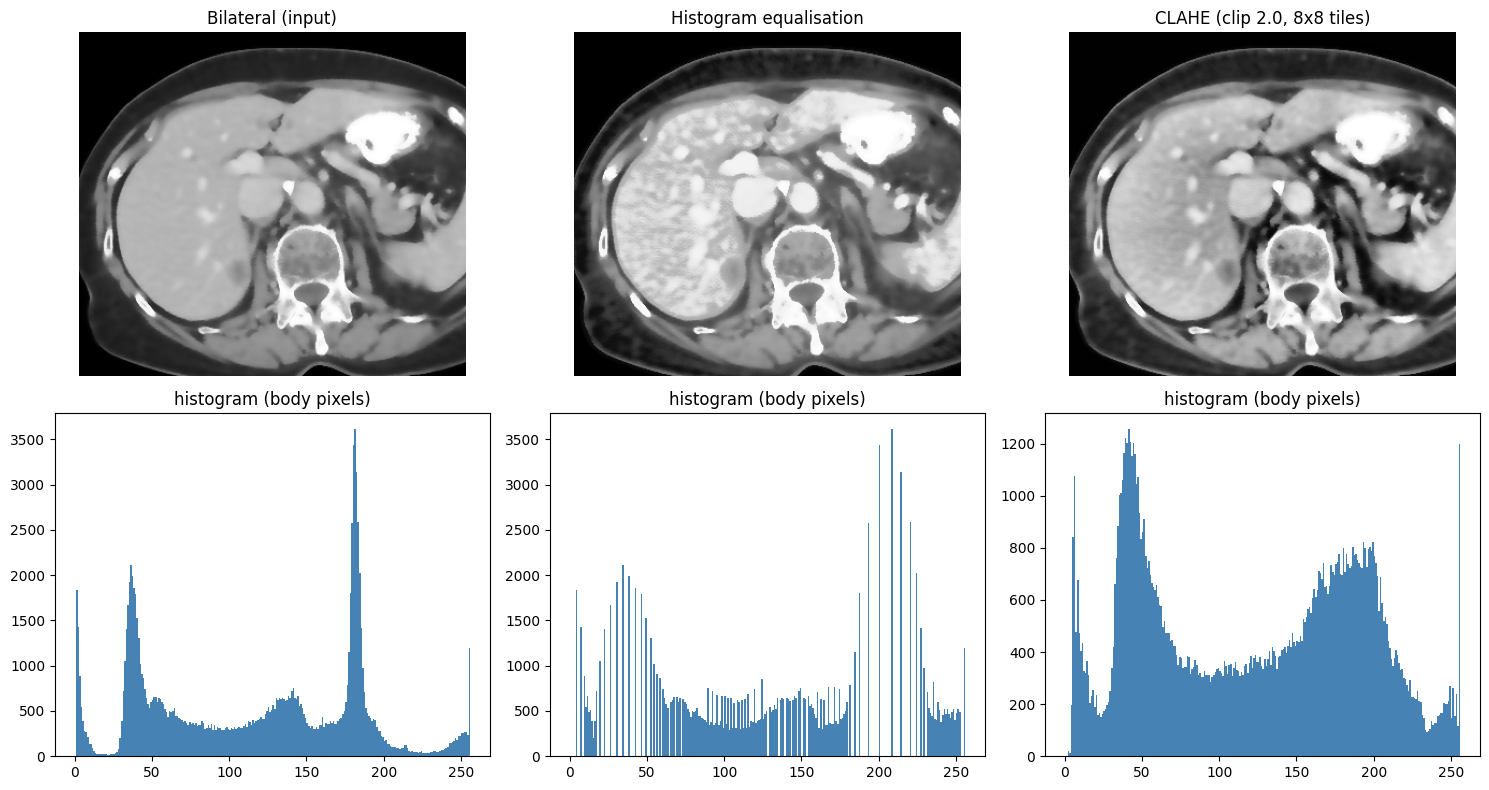

In [4]:
he = cv2.equalizeHist(bilateral)
clahe = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8)).apply(bilateral)

body = bilateral > 0                         # pixels inside the body (ignore the black surround)
fig, ax = plt.subplots(2, 3, figsize=(15, 8))
for j, (im, t) in enumerate([(bilateral, "Bilateral (input)"), (he, "Histogram equalisation"),
                             (clahe, "CLAHE (clip 2.0, 8x8 tiles)")]):
    ax[0, j].imshow(crop(im), cmap="gray"); ax[0, j].set_title(t); ax[0, j].axis("off")
    ax[1, j].hist(im[body].ravel(), bins=256, range=(0, 256), color="steelblue")
    ax[1, j].set_title("histogram (body pixels)")
plt.tight_layout(); plt.savefig(f"{FIGS}/{NAME}_p1_contrast.png", dpi=120); plt.show()

**Frequency domain:** the DFT shows the image as frequencies (centre = smooth shapes, edges = fine detail/noise). The Butterworth lowpass keeps the centre and fades out the rest.

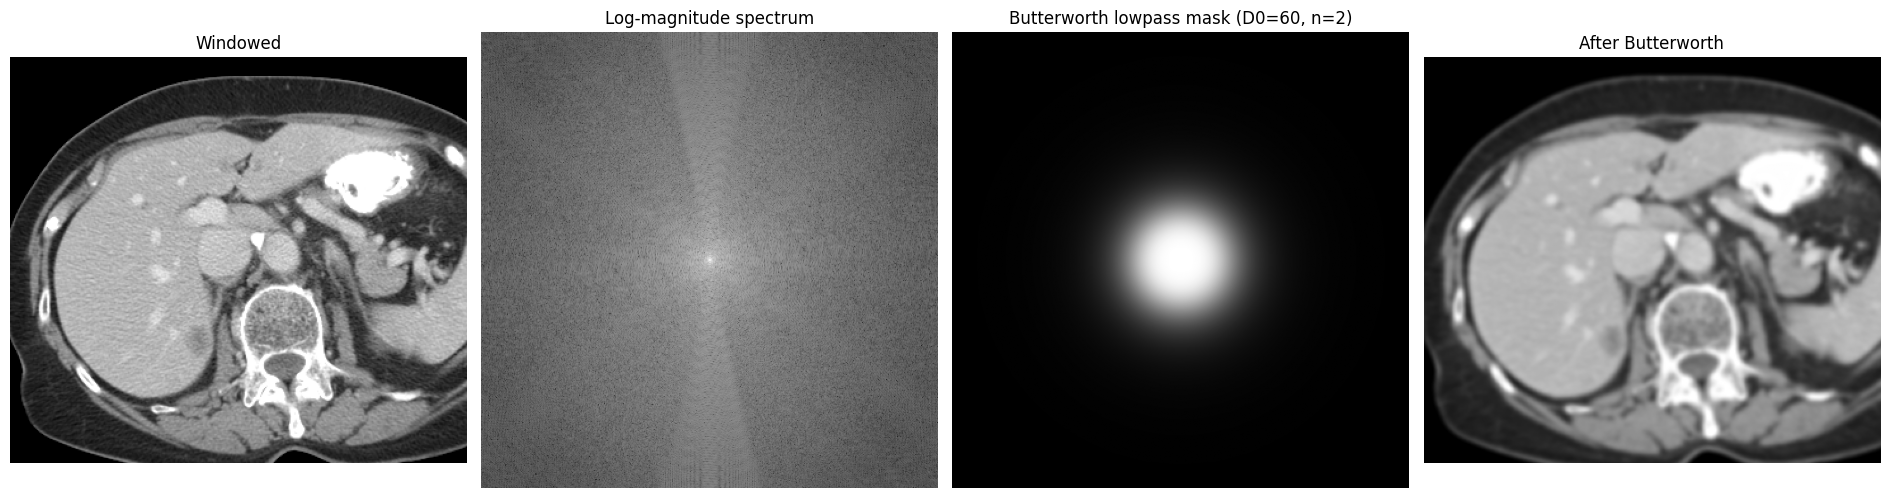

In [5]:
def butterworth_lowpass(img, D0=60, n=2):
    """Filter in the frequency domain: keep low frequencies (smooth shapes), cut high ones (noise)."""
    F = np.fft.fftshift(np.fft.fft2(img.astype(np.float64)))     # DFT, low freqs moved to the centre
    rows, cols = img.shape
    u, v = np.meshgrid(np.arange(cols) - cols / 2, np.arange(rows) - rows / 2)
    D = np.sqrt(u**2 + v**2)                                     # distance from the centre
    H = 1 / (1 + (D / D0) ** (2 * n))                            # Butterworth lowpass formula
    out = np.real(np.fft.ifft2(np.fft.ifftshift(F * H)))         # back to an image
    return np.clip(out, 0, 255).astype(np.uint8), F, H

butter, F, H = butterworth_lowpass(win, D0=60, n=2)
spectrum = np.log(1 + np.abs(F))                                 # log-magnitude spectrum

fig, ax = plt.subplots(1, 4, figsize=(19, 5))
ax[0].imshow(crop(win), cmap="gray"); ax[0].set_title("Windowed")
ax[1].imshow(spectrum, cmap="gray"); ax[1].set_title("Log-magnitude spectrum")
ax[2].imshow(H, cmap="gray"); ax[2].set_title("Butterworth lowpass mask (D0=60, n=2)")
ax[3].imshow(crop(butter), cmap="gray"); ax[3].set_title("After Butterworth")
for a in ax: a.axis("off")
plt.tight_layout(); plt.savefig(f"{FIGS}/{NAME}_p1_frequency.png", dpi=120); plt.show()

**Validation:** PSNR = how much a method changed the image (higher = more faithful); CNR = how much the liver / tumour stands out (higher = easier to segment).

In [6]:
def psnr(ref, test):
    """How close the processed image stays to the original (dB). Higher = less changed."""
    mse = np.mean((ref.astype(np.float64) - test.astype(np.float64)) ** 2)
    return float("inf") if mse == 0 else 10 * np.log10(255 ** 2 / mse)

def cnr(img, region, background):
    """How well a region stands out from its background. Higher = easier to see."""
    a, b = img[region].astype(np.float64), img[background].astype(np.float64)
    return abs(a.mean() - b.mean()) / np.sqrt(a.var() + b.var())

rows = []
for f in files:
    ct, liver, tumour = load(f)
    win = window(ct)
    healthy_liver = liver & ~tumour
    ring = cv2.dilate(liver.astype(np.uint8), np.ones((25, 25), np.uint8)).astype(bool) & ~liver
    bil = cv2.bilateralFilter(win, 9, 40, 9)
    versions = {
        "windowed": win,
        "bilateral": bil,
        "median": cv2.medianBlur(win, 5),
        "butterworth": butterworth_lowpass(win)[0],
        "bilateral+HE": cv2.equalizeHist(bil),
        "bilateral+CLAHE": cv2.createCLAHE(2.0, (8, 8)).apply(bil),
    }
    for method, im in versions.items():
        rows.append({"slice": os.path.basename(f).replace("_ct.npy", ""), "method": method,
                     "PSNR": np.nan if method == "windowed" else psnr(win, im),   # windowed = the reference
                     "CNR liver vs surroundings": cnr(im, liver, ring),
                     "CNR tumour vs liver": cnr(im, tumour, healthy_liver)})

results = pd.DataFrame(rows)
results.to_csv(f"{OUT}/phase1_metrics.csv", index=False)
summary = results.groupby("method", sort=False)[["PSNR", "CNR liver vs surroundings", "CNR tumour vs liver"]].mean().round(2)
print(summary)

                  PSNR  CNR liver vs surroundings  CNR tumour vs liver
method                                                                
windowed           NaN                       1.28                 1.04
bilateral        33.53                       1.31                 1.18
median           27.87                       1.31                 1.21
butterworth      27.98                       1.34                 1.16
bilateral+HE     24.40                       1.43                 1.35
bilateral+CLAHE  26.62                       1.29                 1.22


**Final enhancement chosen:** windowing -> bilateral -> CLAHE. Bilateral had the best PSNR (keeps detail while removing noise); CLAHE looks natural. HE gives a higher tumour CNR but makes the liver grainy (discussion point).

In [7]:
for f in files:
    ct, liver, tumour = load(f)
    enh = cv2.createCLAHE(2.0, (8, 8)).apply(cv2.bilateralFilter(window(ct), 9, 40, 9))
    name = os.path.basename(f).replace("_ct.npy", "_enh.png")
    cv2.imwrite(f"{OUT}/enhanced/{name}", enh)
print("saved", len(files), "enhanced slices to", f"{OUT}/enhanced")

saved 16 enhanced slices to outputs_sama/enhanced
